In [1]:
import numpy as np
from pos_constraints import Ab_i1

In [2]:
# test:
n, d, i, dt = 2, 3, 1, 2.0
A, b = Ab_i1(i, n, d, dt, [1, 2], [3, 4])
print("A =\n", A)
print("b =", b.ravel())
# Expect: cols 6..11 used, cols 0..5 zero
# row0: [0 0 0 0 0 0 | 1 0 0 0 0 0]
# row1: [0 0 0 0 0 0 | 0 1 0 0 0 0]
# row2: [0 0 0 0 0 0 | 1 0 2 0 4 0]
# row3: [0 0 0 0 0 0 | 0 1 0 2 0 4]
# b = [1 2 3 4]

A =
 [[0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 2. 0. 4. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 2. 0. 4.]]
b = [1 2 3 4]


SolutionResult.kSolutionFound


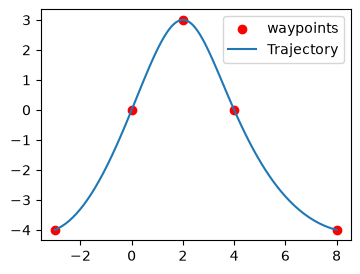

In [10]:
%matplotlib inline
import numpy as np
from math import atan2
import matplotlib.pyplot as plt
import importlib

import minsnap
importlib.reload(minsnap)
from minsnap import minsnap

n = 4;
d = 10;

w = np.zeros((n + 1, 2))
dt = np.ones(n)

w[0] = np.array([-3,-4])
w[1] = np.array([ 0, 0])
w[2] = np.array([ 2, 3])
w[3] = np.array([ 4, 0])
w[4] = np.array([ 8, -4])


# Target trajectory generation
minsnap_trajectory = minsnap(n, d, w, dt)

g = 9.81
t0 = 0
tf = sum(dt)
n_points = 100
t = np.linspace(t0, tf, n_points)

fig = plt.figure(figsize=(4,3))
ax = plt.axes()
ax.scatter(w[:, 0], w[:, 1], c='r', label='waypoints')
ax.plot(minsnap_trajectory(t)[:,0], minsnap_trajectory(t)[:,1], label='Trajectory')
ax.legend()

debugging = False
# Set debugging to true to verify that the derivatives up to 5 are continuous
if debugging:
  fig2 = plt.figure(figsize=(4,3))
  plt.plot(t, minsnap_trajectory(t,1)[:], label='1st derivative')
  plt.legend()

  fig3 = plt.figure(figsize=(4,3))
  plt.plot(t, minsnap_trajectory(t,2)[:], label='2nd derivative')
  plt.legend()

  fig4 = plt.figure(figsize=(4,3))
  plt.plot(t, minsnap_trajectory(t,3)[:], label='3rd derivative')
  plt.legend()

  fig5 = plt.figure(figsize=(4,3))
  plt.plot(t, minsnap_trajectory(t,4)[:], label='4th derivative')
  plt.legend()


plt.show()